# Korpus aufbauen

In [116]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")


[('c:\\workspace\\nlp-lernen\\korpus', [], ['aanrud_sidsel_langroeckchen.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'alarcon-Der Dreispitz.txt', 'alberti-Japanische Märchen.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'goethe-leiden_des_jungen_werther.txt', 'kafka-landarzt.txt', 'kafka-urteil.txt', 'kafka-verwandlung.txt', 'nietzsche-Der tolle Mensch.txt', 'schiller-raeuber.txt', 'Skowronnek-Sturmzeichen.txt', 'westermann-Die Nutzpflanzen unserer Kolonien und ihre wirtschaftliche Bedeutung für das Mutterland.txt'])]
19 Texte wurden erfolgreich in den Korpus geladen.


In [193]:
import nltk
from nltk.text import Text
from nltk.probability import FreqDist
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics

corpus_list = []
#corpus_vec = []
corpus_name = []

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(word):
    return textstatistics().syllable_count(word)

def avg_syllables_per_word(text, words):
    syllable = syllables_count(text)
    ASPW = float(syllable) / float(words)
    #print("Ergebnis von Silben / Wörter:",ASPW)
    return round(ASPW, 1)

def flesch_reading_ease(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)


for element in corpus:
    text = element

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #print("Anzahl Token im Text:",len(nltk_text))
    #print("NLTK:",nltk_text)

    nltk_text_words = [t for t in nltk_text if t.isalpha()]  # Entferne Satzzeichen/Zahlen
    number_words = len(nltk_text_words)
    #print("Wörter im Dokument:",number_words)

    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    number_sentences = len(sentences)
    #print("Sätze im Dokument:",number_sentences) #number of sentences

    avg_sen_len = round(len(nltk_text_words) / len(sentences),1) #average sentence length
    #print(avg_sen_len)
    avg_word_len = round(sum(len(word) for word in nltk_text_words) / len(nltk_text_words),1)
    #print(avg_word_len)
    
    ttr_erg = round(ttr(nltk_text_words),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text,number_words)
    fre_ger = flesch_reading_ease(avg_sen_len, avg_syll)
    print(avg_word_len, avg_sen_len, fre_ger)

    #corpus_list.append([number_sentences, number_words, avg_sen_len, avg_word_len, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    corpus_list.append([avg_word_len, avg_sen_len, fre_ger])
    corpus_name.append(nltk_text)

    #print("-----------------------------------------------")

corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

4.8 20.9 101.9
5.3 19.8 103.0
5.5 15.8 107.1
5.0 20.3 102.6
4.9 24.0 98.8
5.3 16.7 106.2
5.4 17.3 105.6
5.3 17.4 105.5
5.4 16.2 106.7
4.8 8.6 114.1
5.1 13.8 109.2
5.0 24.8 98.4
5.1 22.1 100.7
5.0 21.8 101.2
5.1 28.3 94.5
5.0 24.4 98.8
4.9 10.5 112.6
5.2 16.9 105.9
5.6 12.6 110.7


In [192]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 5.78821570e-04, 1.00606477e-03, 2.78671935e-06,
        4.05333690e-05, 8.57088006e-04, 9.42850749e-04, 1.51217101e-03,
        1.26720151e-03, 8.75746136e-04, 7.68807517e-04, 1.66250089e-01,
        2.45912788e-03, 2.94400257e-02, 1.56967348e-03, 1.67007180e-01,
        9.50417836e-04, 1.02857885e-03, 2.68823197e-05],
       [5.78821570e-04, 0.00000000e+00, 5.89633578e-05, 6.59809898e-04,
        9.11187491e-04, 2.83013646e-03, 2.98780217e-03, 3.95058744e-03,
        3.54132396e-03, 3.46325434e-05, 1.50136235e-05, 1.85504010e-01,
        5.42059656e-03, 3.81956628e-02, 4.01982847e-03, 1.86302780e-01,
        4.80825090e-05, 6.43258587e-05, 4.54937849e-04],
       [1.00606477e-03, 5.89633578e-05, 0.00000000e+00, 1.11146907e-03,
        1.43352299e-03, 3.69574454e-03, 3.87676268e-03, 4.96413137e-03,
        4.50159643e-03, 7.47926271e-06, 1.66993518e-05, 1.91846326e-01,
        6.60577814e-03, 4.12159060e-02, 5.05052882e-03, 1.92655746e-01,
        2.06598449e-06

# Heatmap zeichnen

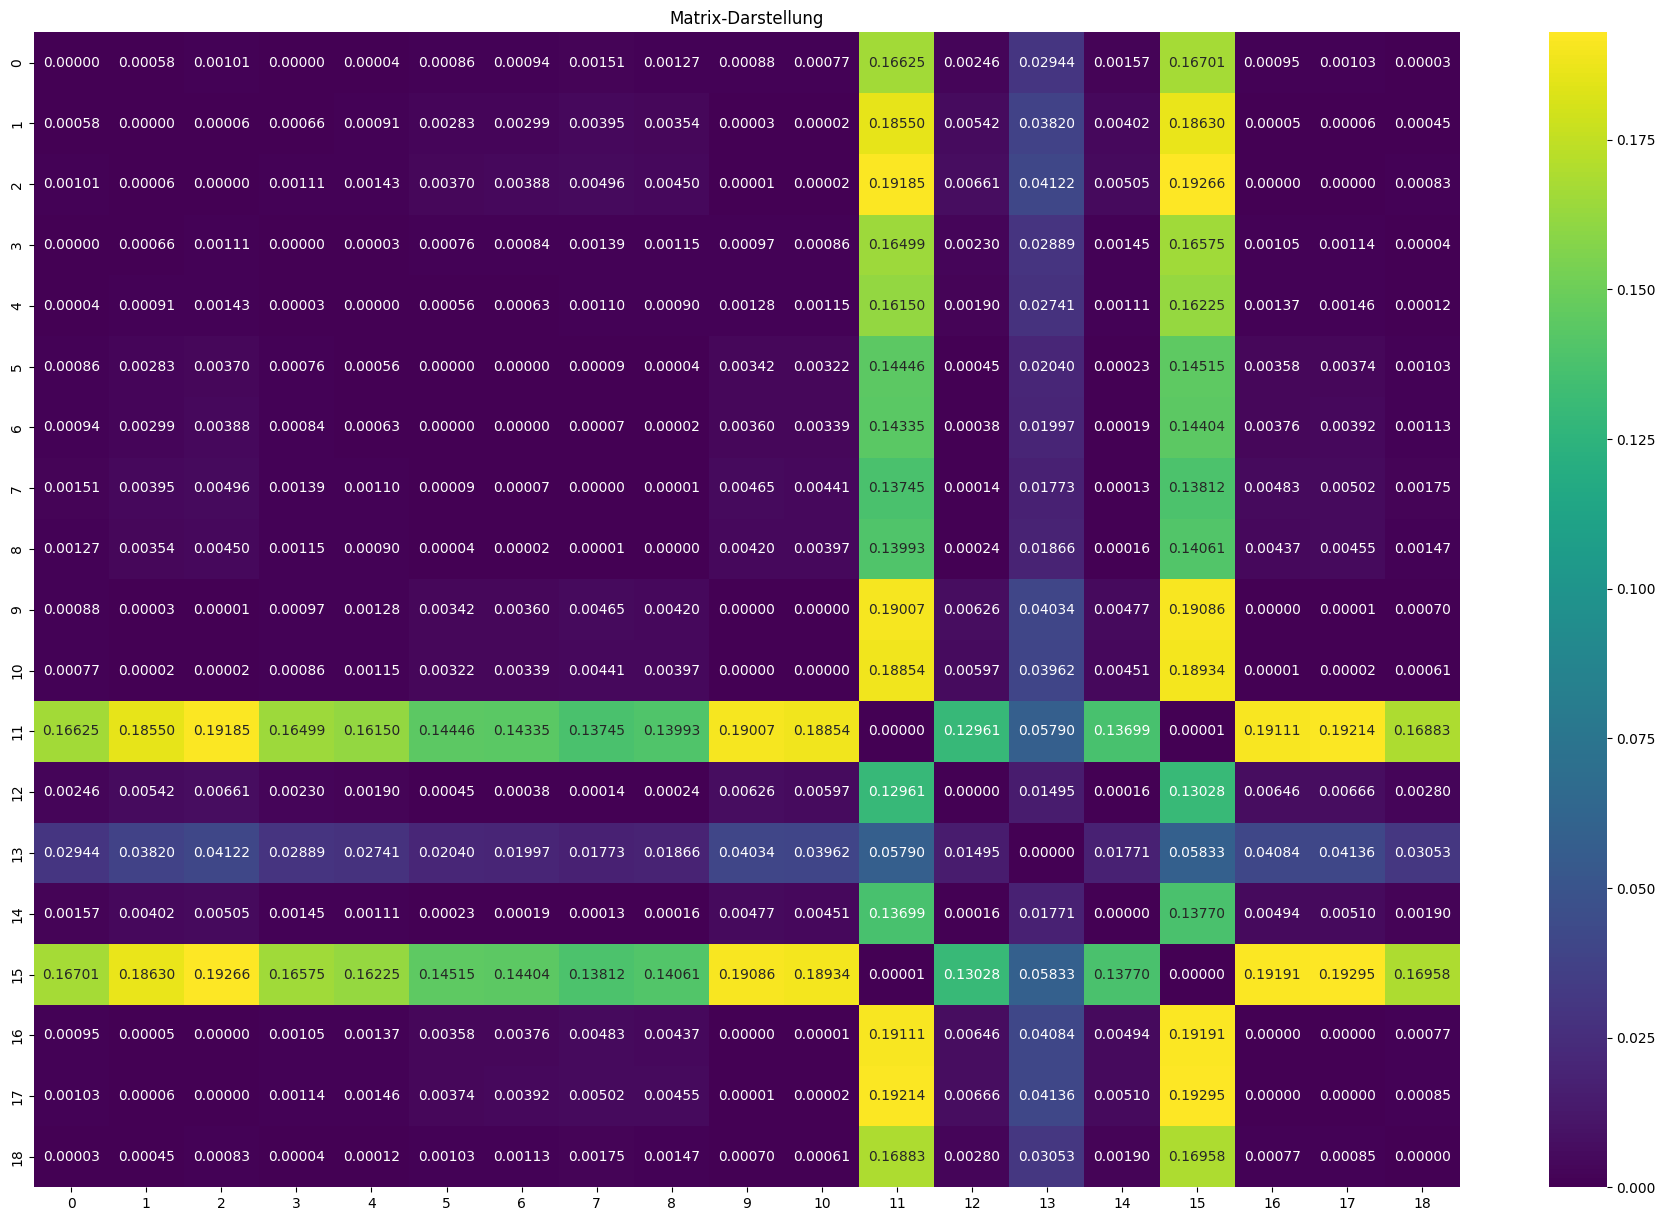

In [191]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(23, 15))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()
